In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_3")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///"+RESULTS_PATH+"/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(f"{param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")

#remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [4]:
from src.models.mtf_model import MTFModel
from src.main import init_dataset

DEVICE = tc.device("cpu")
RUN = "001"
candidates = []
# load test set
full = tc.as_tensor(np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/full.npy", allow_pickle=True))
DATASET = init_dataset(json.load(open(RESULTS_PATH + '/params_ldim=26_relu=12_feature_dim=4_dsr_lr=0p01_lr_gamma=1p00_gtf=0p06_gtf_gamma=1p00_aent=0p89_adsr=114p61_ac=4p55_ar=3p83_asc=0p32_alpha_mar=1p90_mar=0/001/config.json')), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX = {DATASET.evaluator_test_samples[i].measurement_index: DATASET.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 30.


In [5]:
eval_dict = {}
candidates = [subpath for subpath in os.listdir(RESULTS_PATH) if subpath.startswith("params_") and "model_5000.pt" in os.listdir(os.path.join(RESULTS_PATH, subpath, RUN))]
for i, subpath in enumerate(candidates):
    print(subpath)
        
    latent_trajectories = []
    trajectories = []
    run_path = os.path.join(RESULTS_PATH, subpath, RUN)
    model = MTFModel(DATASET, model_path=run_path, device=DEVICE)
    time_series_per_measurement = 4

    nan_counter = 0
    for measurement_index in range(64):
        (latent_trajectory,
         _,
         trajectory,
        ) = (
        model.generate_free_trajectory(
            DATASET.evaluator_test_samples[measurement_index*time_series_per_measurement].input,
            DATASET.evaluator_test_samples[measurement_index*time_series_per_measurement].cumulative_timeseries_index,
            DATASET.evaluator_test_samples[measurement_index*time_series_per_measurement].measurement_index,
            T=50000,
        )[:3]
        )
        trajectory = trajectory[1000:].detach().cpu()
        latent_trajectory = latent_trajectory[1000:].detach().cpu()
        
        klx = klx_bin(trajectory, full[measurement_index]).item()
        pse = power_spectrum_error(trajectory, full[measurement_index][:trajectory.shape[0]]).item()

        if np.isnan(klx) or np.isnan(pse):
            print(f"NaN detected in KL or PSE for subpath: {subpath}, measurement_index: {measurement_index}. Skipping this subpath.")
            nan_counter += 1
            if nan_counter > 4:
                print(f"Too many NaNs for subpath: {subpath}. Moving to next subpath.")
                #break

        trajectories.append(trajectory)
        latent_trajectories.append(latent_trajectory)
    
    eval_dict[subpath] = {"id": i, "trajectory": trajectories, "latent_trajectory": latent_trajectories, "subject_vectors": model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()}

params_ldim=26_relu=12_feature_dim=4_dsr_lr=0p01_lr_gamma=1p00_gtf=0p06_gtf_gamma=1p00_aent=0p89_adsr=114p61_ac=4p55_ar=3p83_asc=0p32_alpha_mar=1p90_mar=0
Encoder model parameters: 5888
DSR model parameters: 3168
Decoder model parameters: 0


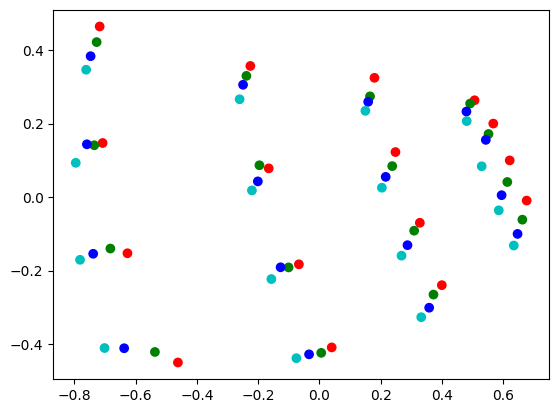

max KL: 15.2141, median KL: 1.8835, PSE: 0.1528, pca: 0.9531481266021729, Subpath: params_ldim=26_relu=12_feature_dim=4_dsr_lr=0p01_lr_gamma=1p00_gtf=0p06_gtf_gamma=1p00_aent=0p89_adsr=114p61_ac=4p55_ar=3p83_asc=0p32_alpha_mar=1p90_mar=0


In [6]:
colors = ["r", "g", "b", "c"]*16
for k, subpath in enumerate(eval_dict.keys()):
    trajectory = eval_dict[subpath]["trajectory"]

    if len(trajectory) < 64:
        continue
    klx_ = []
    pse_ = []
    mse_ = []
    
    for i in range(len(trajectory)):
        klx = klx_bin(trajectory[i], full[i]).item()
        klx_.append(klx)
        pse = power_spectrum_error(trajectory[i], full[i][:trajectory[i].shape[0]],  smoothing_sigma=20, freq_cutoff=4901).item()
        pse_.append(pse)
        mse_.append(tc.nn.functional.mse_loss(trajectory[i], full[i][:trajectory[i].shape[0]]).item())

    pca = PCA(n_components=2)
    subject_vectors = eval_dict[subpath]["subject_vectors"]
    subject_vectors_2d = pca.fit_transform(subject_vectors)
    plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], color=colors)
    plt.show()
    plt.close()
    print("max KL: {:.4f}, median KL: {:.4f}, PSE: {:.4f}, pca: {}, Subpath: {}".format(np.nanmax(klx_), np.nanmedian(klx_), np.nanmedian(pse_), np.sum(pca.explained_variance_ratio_[:3]), subpath))

## Analysis

In [7]:
trial_folder_name = "params_ldim=26_relu=12_feature_dim=4_dsr_lr=0p01_lr_gamma=1p00_gtf=0p06_gtf_gamma=1p00_aent=0p89_adsr=114p61_ac=4p55_ar=3p83_asc=0p32_alpha_mar=1p90_mar=0"
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
model = MTFModel(DATASET, model_path=run_path, device=DEVICE)

Encoder model parameters: 5888
DSR model parameters: 3168
Decoder model parameters: 0


In [8]:
trajectories_train = []
trajectories_val = []
trajectories_test = []

for time_series_index in range(len(DATASET.evaluator_train_samples)):
    observations_train = DATASET.evaluator_train_samples[time_series_index].input
    measurement_index = DATASET.evaluator_train_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_train_samples[time_series_index].cumulative_timeseries_index

    trajectory = model.generate_free_trajectory(
        observations_train,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[0].detach().cpu()
    trajectories_train.append(trajectory)

for time_series_index in range(len(DATASET.evaluator_test_samples)):
    observations_val = DATASET.evaluator_test_samples[time_series_index].input
    measurement_index = DATASET.evaluator_test_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_test_samples[time_series_index].cumulative_timeseries_index

    trajectory = model.generate_free_trajectory(
        observations_val,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[0].detach().cpu()
    trajectories_val.append(trajectory)
    
for i in range(64):
    observations_test = full[i, :270]
    measurement_index = i
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
    
    trajectory = model.generate_free_trajectory(
        observations_test,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[0].detach().cpu()
    trajectories_test.append(trajectory)

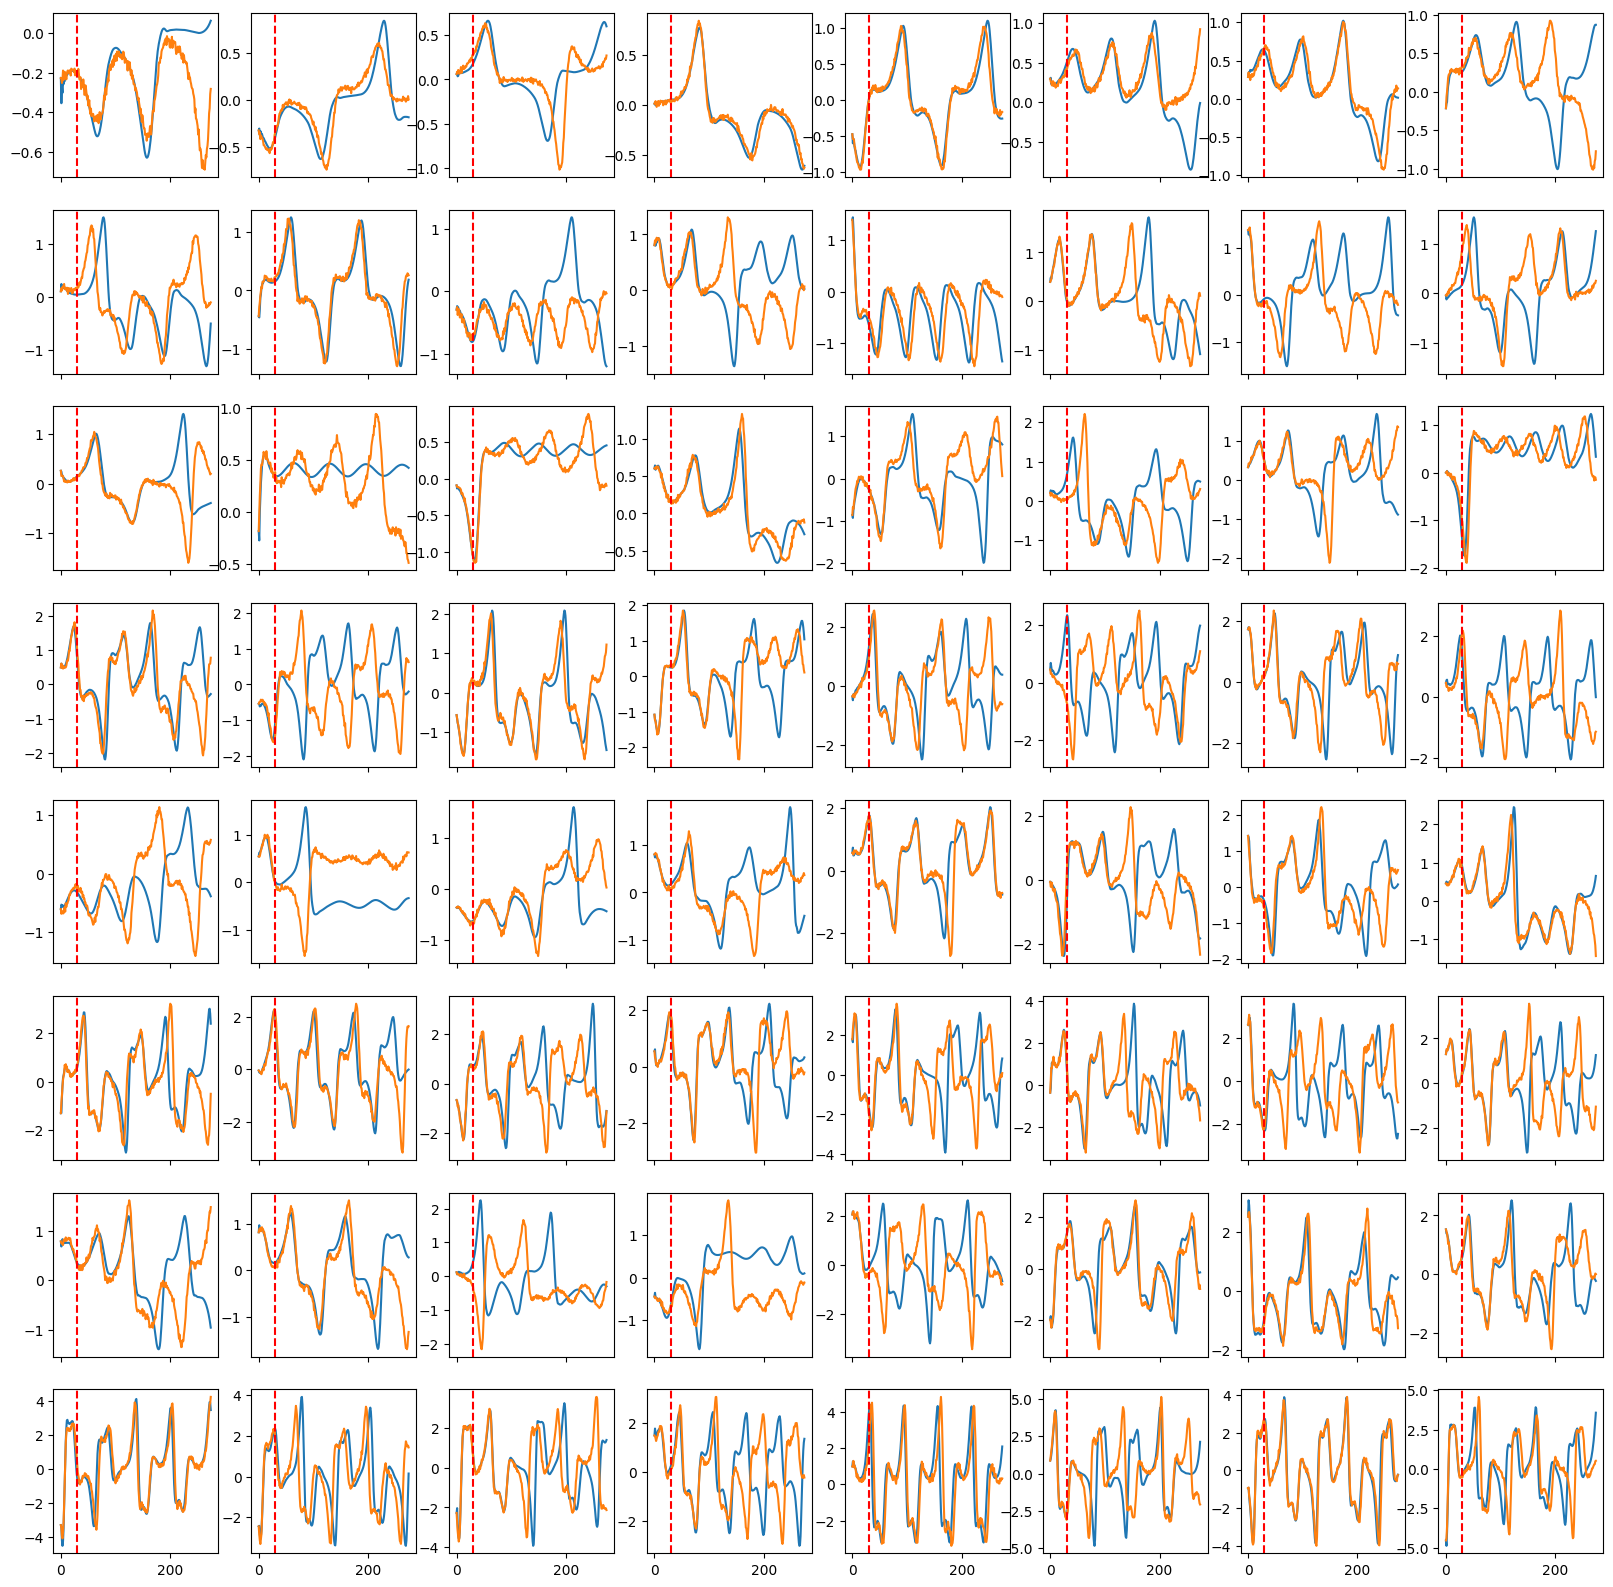

In [10]:
fig, axs = plt.subplots(8, 8, figsize=(20, 20), sharex=True, sharey=False)
for i in range(8):
    for j in range(8):
        idx = (i * 8 + j) * 4 + 0#np.random.randint(0, 4)
        axs[i, j].plot(trajectories_val[idx][:, 1])
        axs[i, j].plot(DATASET.evaluator_test_samples[idx].input[:, 1])
        axs[i, j].axvline(30, color='red', linestyle='--')

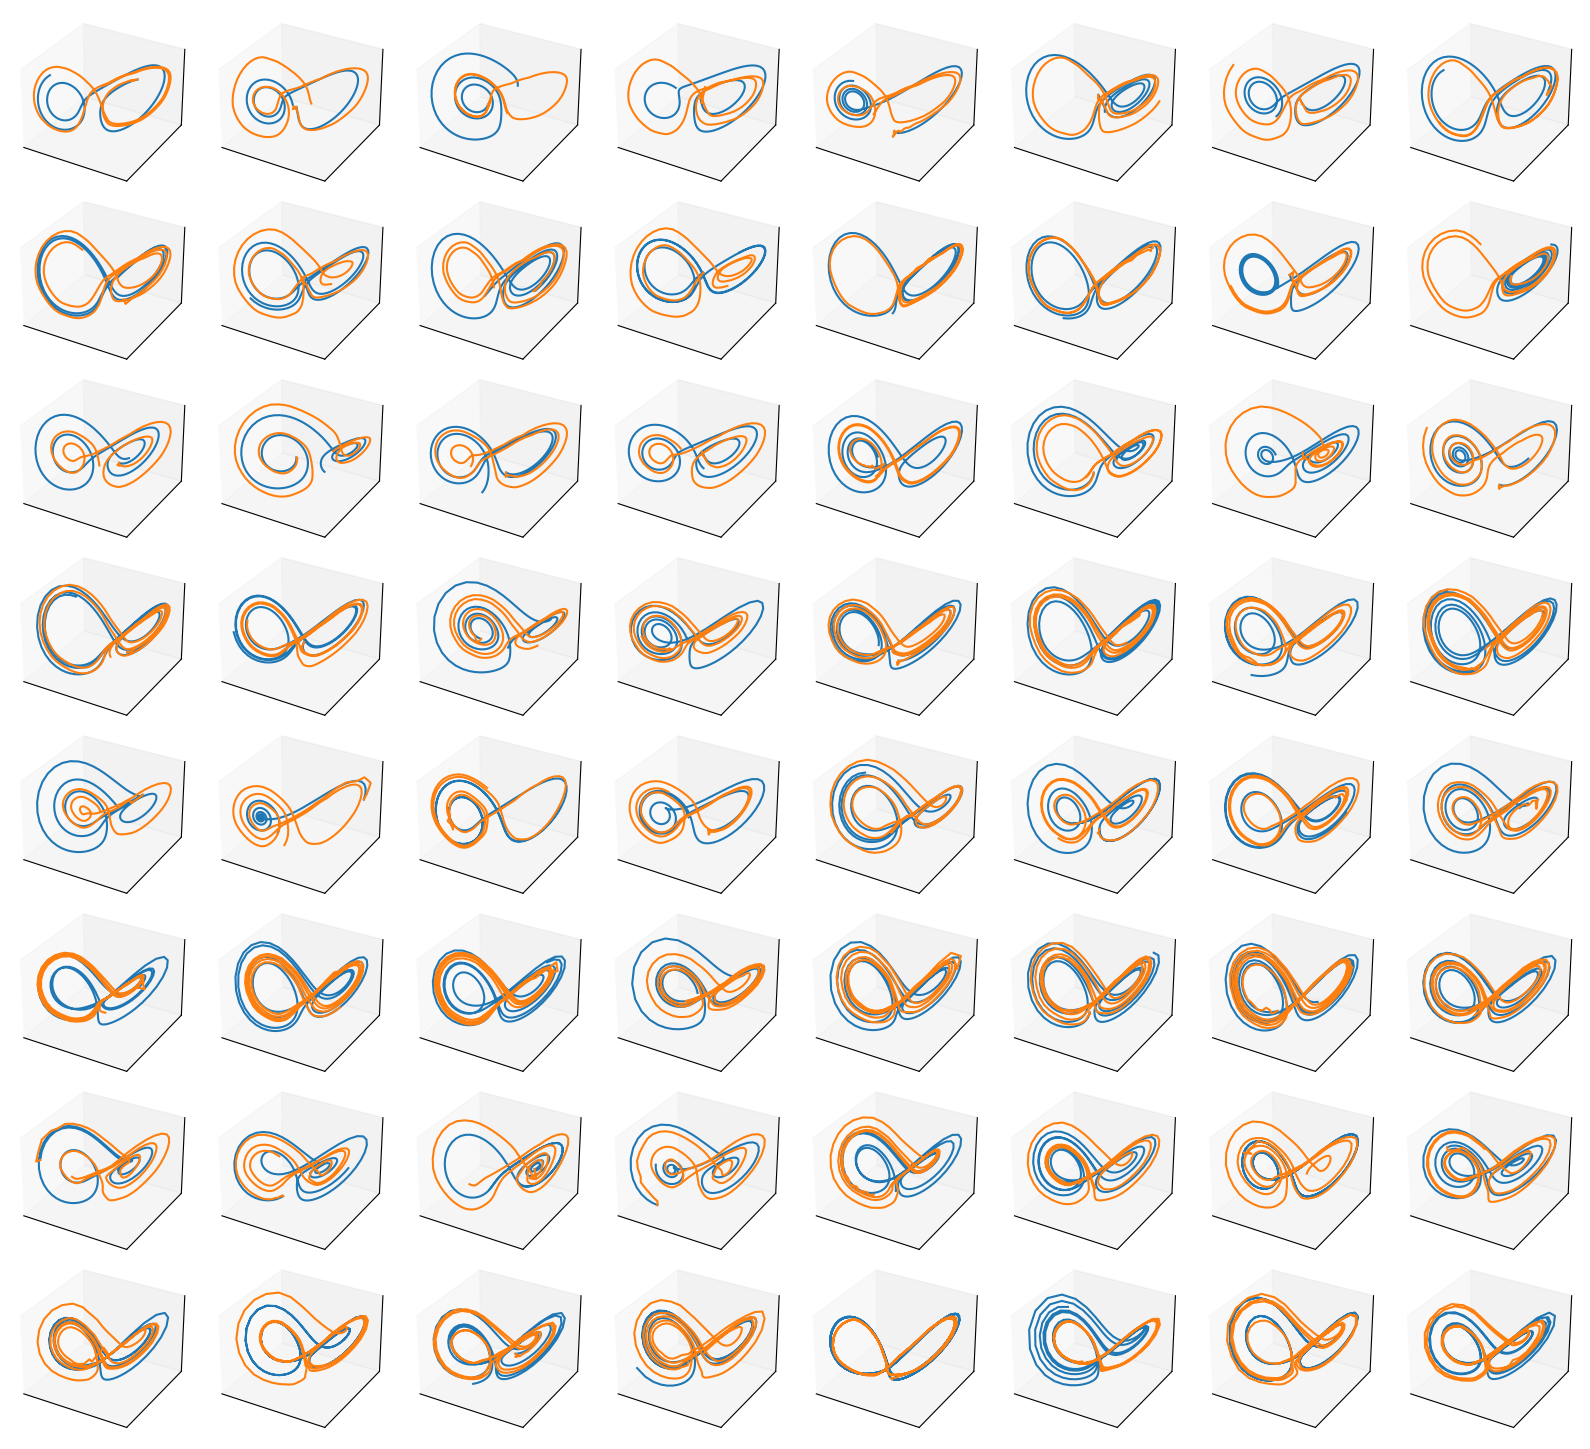

In [ ]:
fig = plt.figure(figsize=(16, 16))

# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)
zlim = (-2, 2)

for i in range(8 * 8):
    ax = fig.add_subplot(8, 8, i + 1, projection='3d')

    # Plot data
    ax.plot(full[i][:300, 0],
            full[i][:300, 1],
            full[i][:300, 2])
    ax.plot(trajectories_test[i][:, 0],
            trajectories_test[i][:, 1],
            trajectories_test[i][:, 2])

    # Set shared limits
    #ax.set_xlim(xlim)
    #ax.set_ylim(ylim)
    #ax.set_zlim(zlim)

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()
#save_fig(fig, "lorenz_3d_reconstruction")

Text(0, 0.5, 'PC 2')

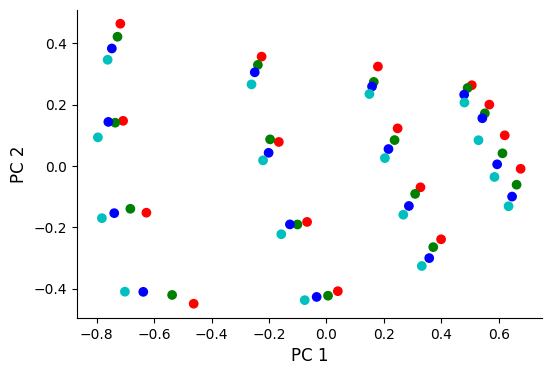

In [15]:
colors = ["r", "g", "b", "c"]*16
#colors = ["r", "r", "r", "r", "g", "g", "g", "g", "b", "b", "b", "b", "c", "c", "c", "c"]*4
#colors = ["r"]*16 + ["g"]*16 + ["b"]*16 + ["c"]*16

subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
# pca
pca = PCA(n_components=2)
subject_vectors_2d = pca.fit_transform(model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy())
fig = plt.figure(figsize=(6, 4))
plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], color=colors)
# top and right spines removed
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel("PC 1", fontsize=FONT_SIZE)
plt.ylabel("PC 2", fontsize=FONT_SIZE)
#save_fig(fig, "hier_lorenz_subject_vectors_pca")

## Fine Tuning

In [13]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "hier_lorenz_ft")
DATASET_FT = init_dataset(json.load(open(RESULTS_PATH + "/params_dsr_lr=0p03_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=14p17_adsr=39p07_ac=2p13_asc=0p00_alpha_mar=0p00/001/config.json")), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX_FT = {DATASET_FT.evaluator_test_samples[i].measurement_index: DATASET_FT.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET_FT.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 30.


In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(f"{param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

In [17]:
device = tc.device("cpu")
eval_dict = {}
# load test set
full_ft = tc.as_tensor(np.load(DATA_DIR + "/multi_task_lorenz63/no_spirals/full_FT.npy", allow_pickle=True)).permute(1, 0, 2)

In [18]:
trial = get_trial_by_number(study.trials, 106)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)

params_dsr_lr=0p06_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=0p22_adsr=1p47_ac=0p27_asc=0p94_alpha_mar=12p57


In [19]:
trial_folder_name = "params_dsr_lr=0p03_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=14p17_adsr=39p07_ac=2p13_asc=0p00_alpha_mar=0p00"
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
parameters = json.load(open(f"{run_path}/config.json"))
model_ft = MTFModel(DATASET_FT, model_path=run_path, device=DEVICE)

Encoder model parameters: 5888
DSR model parameters: 3168
Decoder model parameters: 0


In [20]:
trajectories_train = []
trajectories_val = []
trajectories_test = []

for time_series_index in range(len(DATASET.evaluator_train_samples)):
    observations_train = DATASET.evaluator_train_samples[time_series_index].input
    measurement_index = DATASET.evaluator_train_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_train_samples[time_series_index].cumulative_timeseries_index

    trajectory = model_ft.generate_free_trajectory(
        observations_train,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[0].detach().cpu()
    trajectories_train.append(trajectory)

for time_series_index in range(len(DATASET.evaluator_test_samples)):
    observations_val = DATASET.evaluator_test_samples[time_series_index].input
    externals_val = DATASET.evaluator_test_samples[time_series_index].external
    measurement_index = DATASET.evaluator_test_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_test_samples[time_series_index].cumulative_timeseries_index

    trajectory = model_ft.generate_free_trajectory(
        observations_val,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[0].detach().cpu()
    trajectories_val.append(trajectory)

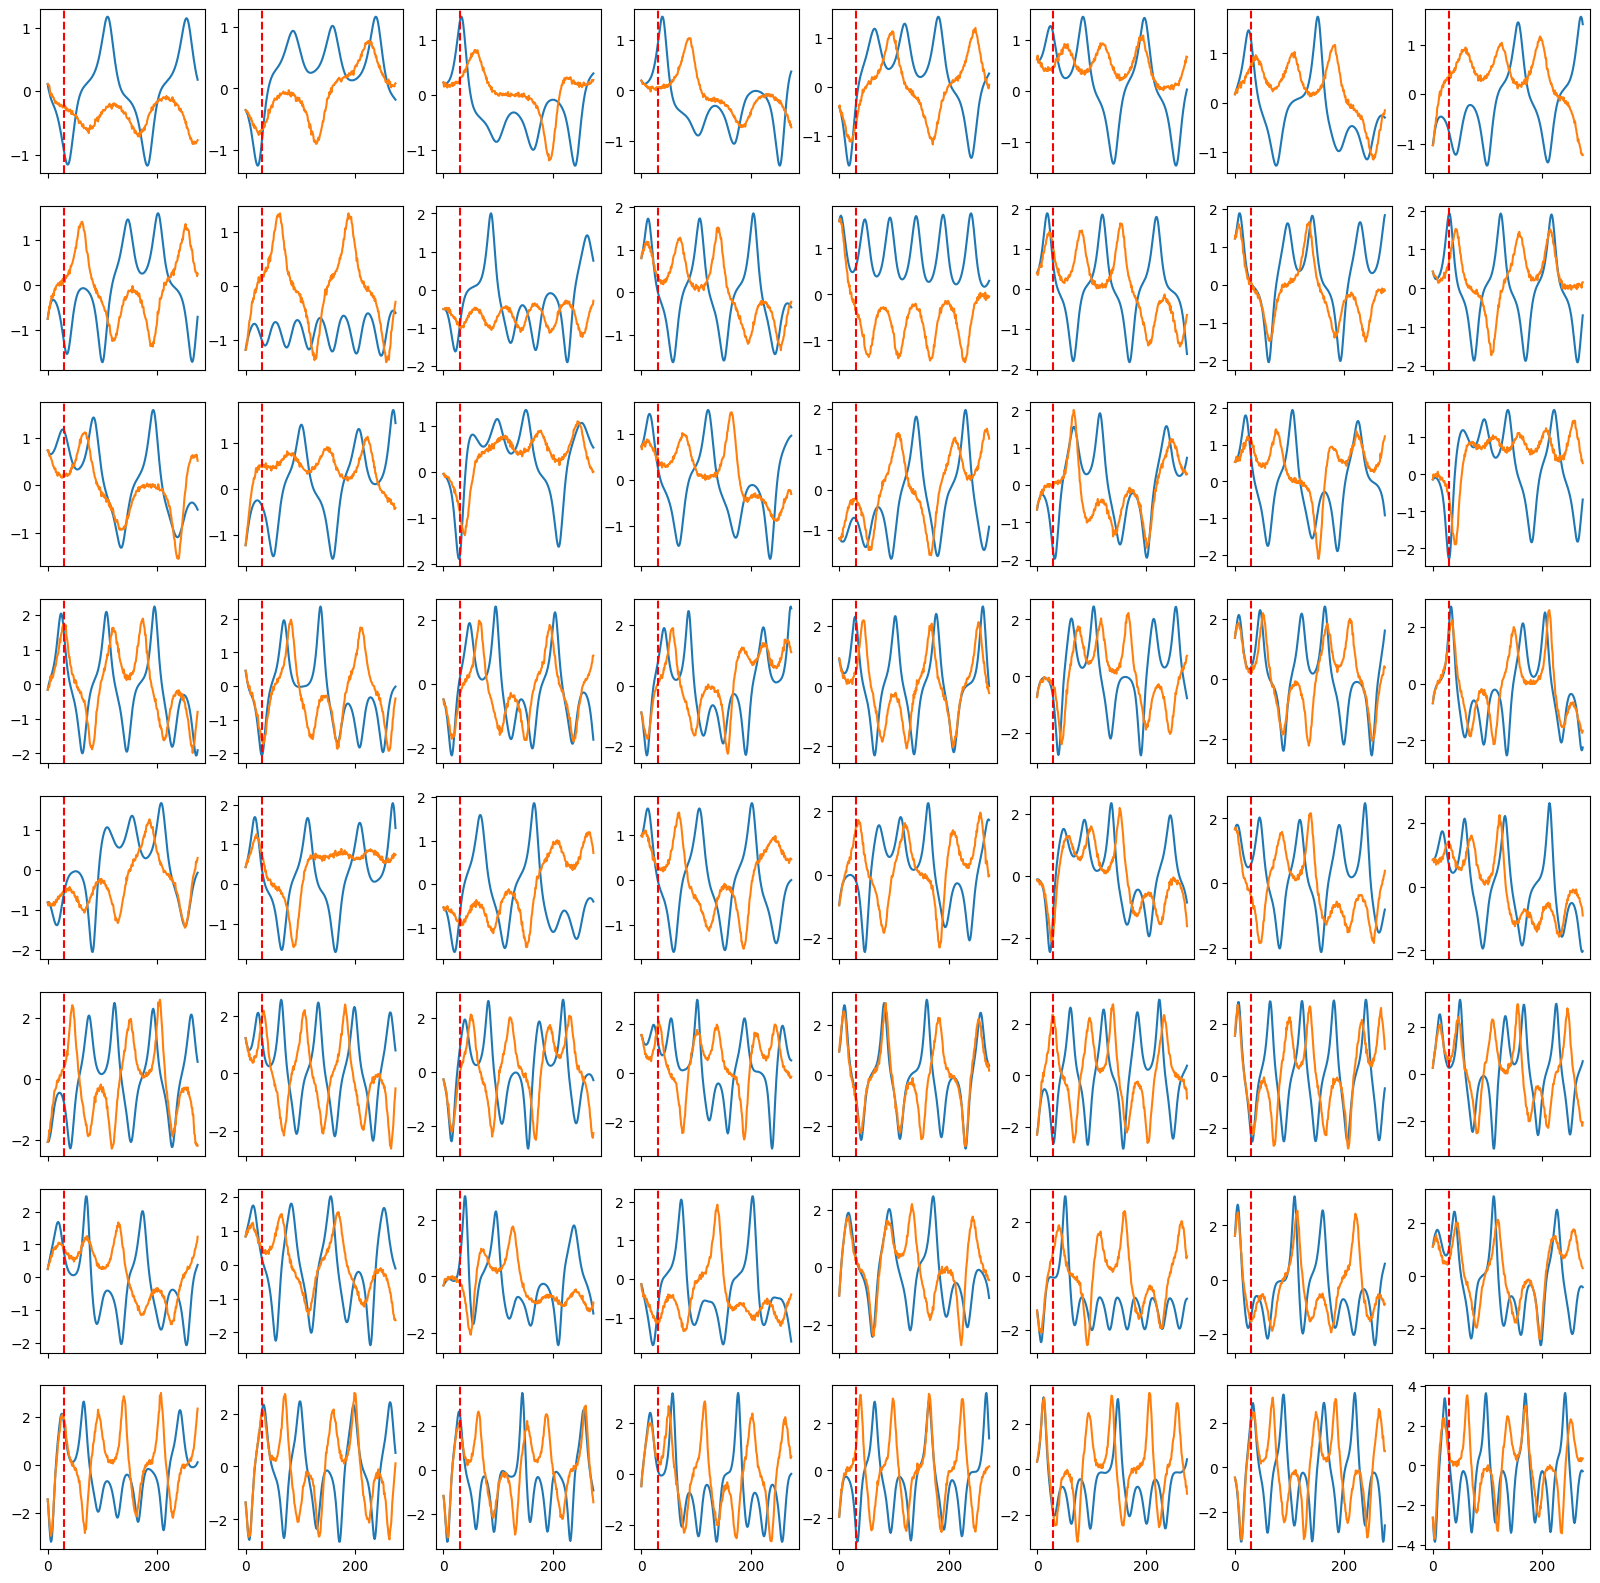

In [21]:
fig, axs = plt.subplots(8, 8, figsize=(20, 20), sharex=True, sharey=False)
for i in range(8):
    for j in range(8):#
        idx = (i * 8 + j) * 4 #+ np.random.randint(0, 4)
        axs[i, j].plot(trajectories_val[idx][:, 0])
        axs[i, j].plot(DATASET.evaluator_test_samples[idx].input[:, 0])
        axs[i, j].axvline(30, color='red', linestyle='--')

In [22]:
assert (model_ft.dsr_model.latent_step_params.group["P_W"] == model.dsr_model.latent_step_params.group["P_W"]).all()
assert not (model_ft.dsr_model.latent_step_params.subject_vectors == model.dsr_model.latent_step_params.subject_vectors).all()

In [ ]:
eval_dict = {}
candidates = [subpath for subpath in os.listdir(RESULTS_PATH) if subpath.startswith("params_") and "001" in os.listdir(os.path.join(RESULTS_PATH, subpath))
              and "model_5000.pt" in os.listdir(os.path.join(RESULTS_PATH, subpath, RUN))]

for i, subpath in enumerate(os.listdir(RESULTS_PATH)):
    if not subpath in candidates:
        continue
    if not subpath == "params_dsr_lr=0p03_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=14p17_adsr=39p07_ac=2p13_asc=0p00_alpha_mar=0p00":
        continue

    latent_trajectories = []
    trajectories = []
    run_path = os.path.join(RESULTS_PATH, subpath, RUN)
    model = MTFModel(DATASET_FT, model_path=run_path, device=DEVICE)
    time_series_per_measurement = 4

    nan_counter = 0
    for measurement_index in range(64):
        (latent_trajectory,
         _,
         trajectory,
        ) = (
        model.generate_free_trajectory(
            DATASET_FT.evaluator_test_samples[measurement_index*time_series_per_measurement].input[tc.randint(0, 200, (1,))],
            DATASET_FT.evaluator_test_samples[measurement_index*time_series_per_measurement].cumulative_timeseries_index,
            DATASET_FT.evaluator_test_samples[measurement_index*time_series_per_measurement].measurement_index,
            T=50000,
        )[:3]
        )
        trajectory = trajectory[1000:].detach().cpu()
        latent_trajectory = latent_trajectory[1000:].detach().cpu()
        
        klx = klx_bin(trajectory, full_ft[measurement_index]).item()
        pse = power_spectrum_error(trajectory, full_ft[measurement_index][:trajectory.shape[0]]).item()

        if np.isnan(klx) or np.isnan(pse):
            print(f"NaN detected in KL or PSE for subpath: {subpath}, measurement_index: {measurement_index}.")
            nan_counter += 1
            if nan_counter > 4:
                print(f"Too many NaNs for subpath: {subpath}. Moving to next subpath.")
                break

        trajectories.append(trajectory)
        latent_trajectories.append(latent_trajectory)
    
    eval_dict[subpath] = {"id": i, "trajectory": trajectories, "latent_trajectory": latent_trajectories, "subject_vectors": model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()}

In [ ]:
colors = ["r", "g", "b", "c"]*16
#colors = ["r", "r", "r", "r", "g", "g", "g", "g", "b", "b", "b", "b", "c", "c", "c", "c"]*4

for k, subpath in enumerate(eval_dict.keys()):

    trajectory = eval_dict[subpath]["trajectory"]

    if len(trajectory) < 64:
        #shutil.rmtree(os.path.join(RESULTS_PATH, subpath))
        continue
    klx_ = []
    pse_ = []
    mse_ = []
    
    for i in range(len(trajectory)):
        klx = klx_bin(trajectory[i], full_ft[i]).item()
        klx_.append(klx)
        pse = power_spectrum_error(trajectory[i], full_ft[i][:trajectory[i].shape[0]],  smoothing_sigma=20, freq_cutoff=4901).item()
        pse_.append(pse)
        mse = tc.nn.functional.mse_loss(trajectory[i], full_ft[i][:trajectory[i].shape[0]]).item()
        mse_.append(mse)

    pca = PCA(n_components=2)
    subject_vectors = eval_dict[subpath]["subject_vectors"]
    subject_vectors_2d = pca.fit_transform(subject_vectors)
    plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], color=colors)
    plt.show()
    plt.close()
    if np.nanmedian(klx_)> 14:
        try:
            print(f"Removed subpath: {subpath} due to high KL divergence.")
            #shutil.rmtree(os.path.join(RESULTS_PATH, subpath))
        except Exception as e:
            print(f"Error removing subpath: {subpath}. Exception: {e}")

    print("KL: {:.4f}, PSE: {:.4f}, MSE: {:.4f}, Subpath: {}".format(np.nanmedian(klx_), np.nanmedian(pse_), np.nanmedian(mse_), subpath))